In [ ]:
import contextily as cx
import geopandas as gpd
import pandas as pd

In [ ]:
aws_ts_df_filepath = "../data/interim/aws-ts-df.csv"
lcd_ts_df_filepath = "../data/interim/lcd-ts-df.csv"

aws_stations_gdf_filepath = "../data/interim/aws-stations.gpkg"
lcd_stations_gdf_filepath = "../data/interim/lcd-stations.gpkg"

stations_crs = "epsg:2056"
source_labels = ["AWS", "LCD"]

dst_station_id_col = "station_id"
dst_stations_gdf_filepath = "../data/processed/stations.gpkg"
dst_ts_df_filepath = "../data/processed/ts-df.csv"

In [ ]:
# merge both data sources: resample each to hourly and concatenate along columns
ts_df = pd.concat(
    [
        pd.concat(
            [
                heatwave_ts_df.loc[heatwave]
                .resample("h")
                .mean()
                .assign(**{"heatwave": heatwave})
                for heatwave, heatwave_ts_df in pd.read_csv(
                    ts_df_filepath,
                    index_col=["heatwave", "time"],
                    parse_dates=["time"],
                ).groupby("heatwave")
            ],
            axis="rows",
        )
        for ts_df_filepath in [aws_ts_df_filepath, lcd_ts_df_filepath]
    ],
    axis="columns",
)
# deduplicate heatwave column from the two sources, restore MultiIndex
ts_df = (
    ts_df.loc[:, ~ts_df.columns.duplicated()]
    .reset_index()
    .set_index(["heatwave", "time"])
)
ts_df

KLO        REH        SMA  \
heatwave              time                                                   
2022-06-16/2022-06-20 2022-06-16 00:00:00  19.533333  18.366667  21.433333   
                      2022-06-16 01:00:00  18.883333  17.683333  20.383333   
                      2022-06-16 02:00:00  18.233333  18.416667  19.033333   
                      2022-06-16 03:00:00  18.100000  17.333333  17.816667   
                      2022-06-16 04:00:00  18.233333  17.783333  17.633333   
...                                              ...        ...        ...   
2025-08-12/2025-08-16 2025-08-16 19:00:00  24.000000  24.083333  23.600000   
                      2025-08-16 20:00:00  23.383333  23.333333  22.583333   
                      2025-08-16 21:00:00  22.150000  22.850000  21.916667   
                      2025-08-16 22:00:00  19.650000  21.333333  21.000000   
                      2025-08-16 23:00:00  18.966667  19.916667  20.283333   

                                           Zürich-Kaserne  Dübendorf-Empa  \
heatwave              time                                                  
2022-06-16/2022-06-20 2022-06-16 00:00:00            24.6            22.1   
                      2022-06-16 01:00:00            23.7            21.0   
                      2022-06-16 02:00:00            22.8            20.4   
                      2022-06-16 03:00:00            22.2            19.6   
                      2022-06-16 04:00:00            21.0            19.6   
...                                                   ...             ...   
2025-08-12/2025-08-16 2025-08-16 19:00:00            27.7            26.7   
                      2025-08-16 20:00:00            26.9            25.7   
                      2025-08-16 21:00:00            26.0            24.5   
                      2025-08-16 22:00:00            24.9            23.5   
                      2025-08-16 23:00:00            24.3            22.9   

                                              A10      A7  B12      B3  \
heatwave              time                                               
2022-06-16/2022-06-20 2022-06-16 00:00:00     NaN     NaN  NaN  21.550   
                      2022-06-16 01:00:00     NaN     NaN  NaN  21.125   
                      2022-06-16 02:00:00     NaN     NaN  NaN  19.450   
                      2022-06-16 03:00:00     NaN     NaN  NaN  17.750   
                      2022-06-16 04:00:00     NaN     NaN  NaN  18.075   
...                                           ...     ...  ...     ...   
2025-08-12/2025-08-16 2025-08-16 19:00:00  22.675  25.850  NaN  25.150   
                      2025-08-16 20:00:00  22.700  24.975  NaN  24.250   
                      2025-08-16 21:00:00  22.625  24.400  NaN  23.675   
                      2025-08-16 22:00:00  21.275  23.575  NaN  23.000   
                      2025-08-16 23:00:00  20.300  22.175  NaN  21.750   

                                               B6  ...       2680       2681  \
heatwave              time                         ...                         
2022-06-16/2022-06-20 2022-06-16 00:00:00  20.900  ...        NaN        NaN   
                      2022-06-16 01:00:00  20.475  ...        NaN        NaN   
                      2022-06-16 02:00:00  19.700  ...        NaN        NaN   
                      2022-06-16 03:00:00  18.125  ...        NaN        NaN   
                      2022-06-16 04:00:00  18.525  ...        NaN        NaN   
...                                           ...  ...        ...        ...   
2025-08-12/2025-08-16 2025-08-16 19:00:00  25.700  ...  26.660000  25.211667   
                      2025-08-16 20:00:00  24.850  ...  25.843333  24.184000   
                      2025-08-16 21:00:00  24.425  ...  25.086667  23.641667   
                      2025-08-16 22:00:00  23.575  ...  24.456667  22.752500   
                      2025-08-16 23:00:00  22.300  ...  23.780000  21.961667   

                            

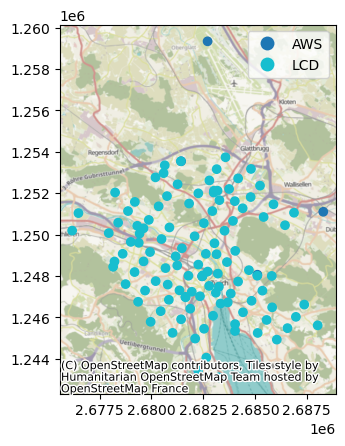

In [ ]:
stations_gdf = (
    pd.concat(
        [
            gpd.read_file(stations_gdf_filepath)
            .to_crs(stations_crs)
            .rename(columns={"index": dst_station_id_col})[
                [dst_station_id_col, "geometry"]
            ]
            .assign(source=source)
            for stations_gdf_filepath, source in zip(
                [aws_stations_gdf_filepath, lcd_stations_gdf_filepath],
                source_labels,
            )
        ]
    )
    .set_index(dst_station_id_col)
    .loc[ts_df.columns]
    .reset_index(names=dst_station_id_col)
)
ax = stations_gdf.plot("source", legend=True)
cx.add_basemap(ax, crs=stations_gdf.crs)

In [ ]:
stations_gdf["source"].value_counts()

source
LCD    113
AWS      5
Name: count, dtype: int64

In [ ]:
ts_df.to_csv(dst_ts_df_filepath)
stations_gdf.to_file(dst_stations_gdf_filepath)